<div dir="rtl" style="text-align:right"><h1>שיעור 2 | איך מכונה לומדת?</h1><p>יישומי בינה מלאכותית AI | גל דנינו | 21.10.2026</p><p>נחקור את איכות הנתונים, ואז סיווג והתאמת יתר. אשכול הוא הדגמה קצרה והרחבה לבחירה. הכול באמצעות נתונים בדויים. אין צורך בידע מוקדם בתכנות. זו מחברת להתנסות: <b>אין חובת הגשת מחברת</b>.</p><h2>פותחים בגוגל קולאב</h2><p>פתחו את colab.research.google.com, בחרו פתיחת מחברת והעלו את קובץ ה-ipynb. שמרו עותק ב-Drive אם תרצו לשמור שינויים. התקדמו סעיף אחר סעיף באמצעות כפתור ההפעלה; עצרו בכל שאלה לפני צפייה בתשובה. בסעיף 3 משנים רק את שתי ההגדרות בראש התא. אחרי סעיף 6 אפשר לדלג על הרחבה 7 ולעבור למבחן הסופי בסעיף 8. המבחן נשאר סגור עד שתאשרו בו בחירה מנומקת. CPU רגיל מספיק; אין צורך ב-GPU, מפתח API או מנוי בתשלום. הגרפים באנגלית כדי לשמור על תצוגה תקינה; ההנחיות בעברית.</p><p>אם מופיעה בקשת התחברות, השתמשו בחשבון שמותר לכם להשתמש בו. אם החיבור לסביבת הריצה נותק, התחברו והריצו שוב מההתחלה. הנתונים נוצרים כאן ואינם יורדים ממקור חיצוני.</p></div>

<div dir="rtl" style="text-align:right"><h2>1 | לפני הריצה: מה בדיוק חוזים?</h2><p>חנות רוצה לצפות מי מלקוחותיה יקנה בשבוע הבא. לכל שורה יש מספר ביקורים ב-30 הימים האחרונים, ימים מאז הרכישה האחרונה, ותשובה היסטורית: האם הלקוח קנה בשבוע שלאחר נקודת המדידה. שני המשתנים הראשונים הם <b>תכונות</b>; התשובה היא <b>תווית</b>. נלמד מסיווג של דוגמאות ישנות כדי לחזות דוגמה חדשה.</p><p><b>הכול בדוי:</b> נוסחה אקראית יוצרת את התשובות לצורכי הוראה. אין להסיק ממנה על לקוחות אמיתיים או על השפעת שליחת פרסומת. כל התכונות נמדדות לפני השבוע שאותו חוזים.</p><blockquote>לפני ההרצה, כתבו כלל משלכם: לפי אילו ערכים תנחשו שהלקוח יקנה?</blockquote></div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, ConfusionMatrixDisplay
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(42)
n = 1200
visits = rng.integers(0, 21, n)
days = rng.integers(0, 61, n)
signal = -1.5 + 0.28 * visits - 0.055 * days + np.sin(visits / 2)
probability = 1 / (1 + np.exp(-signal))
bought = (rng.random(n) < probability).astype(int)
data = pd.DataFrame({'visits_30d': visits, 'days_since_purchase': days, 'bought_next_week': bought})
X = data[['visits_30d', 'days_since_purchase']]
y = data['bought_next_week']
print('Synthetic customers:', len(data))
display(data.head(10))

Synthetic customers: 1200


,visits_30d,days_since_purchase,bought_next_week
0,1,53,0
1,16,29,1
2,13,60,0
3,9,46,0
4,9,39,1
5,18,55,1
6,1,31,0
7,14,43,1
8,4,17,1
9,1,58,0


<div dir="rtl" style="text-align:right"><h2>1א | מעבירים את הנתונים לצ׳טבוט לפני הבדיקה</h2><p><b>הסדר: מכינים קובץ ← מורידים ← מצרפים לצ׳טבוט ← מבקשים בדיקות ← מריצים בקולאב.</b> הצ׳טבוט אינו רואה את המחברת או את המשתנה raw רק משום שהם פתוחים אצלכם.</p><ol><li>הריצו את תא ההכנה הבא. הוא יוצר עותק בדוי עם תקלות ואת הקובץ <code>lesson2-customer-data.csv</code>.</li><li>לחצו על <b>Download CSV</b>, חזרו לצ׳טבוט וצרפו את הקובץ שהורד. המתינו לסיום ההעלאה.</li><li>שלחו את הבקשה שלהלן עם הקובץ. בקשו שיציג שמות עמודות ודוגמת שורות כדי לוודא שניגש לתוכן.</li><li>קבלו תוכנית בדיקה וקוד Python. הוסיפו תא קוד חדש בקולאב, אחרי תא ההכנה, והדביקו והריצו בו את הקוד. לאחר מכן השוו לבדיקות המוכנות בהמשך.</li></ol><p>שורה אמורה לייצג לקוח אחד בנקודת מדידה אחת. הנתונים בדויים בלבד; אין לצרף נתוני לקוחות אמיתיים.</p><blockquote>קרא את קובץ ה-CSV המצורף. אם אינך יכול לגשת לתוכן שלו, אמור זאת ואל תנחש. הצג שמות עמודות ושתי שורות לדוגמה. כל שורה היא לקוח בנקודת מדידה אחת. customer_id הוא מזהה לבדיקה בלבד; visits_30d הוא מספר ביקורים ב-30 הימים הקודמים, בטווח התרגיל 0 עד 20; days_since_purchase הוא ימים מאז הרכישה, בטווח התרגיל 0 עד 60; bought_next_week היא תווית היסטורית 0 או 1, לא תכונת קלט. הצע בדיקות לחסרים, מזהים כפולים וחריגות, והסבר מה כל בדיקה מבררת. אל תמלא ואל תמחק ערכים. כתוב קוד Python לקולאב: הטבלה כבר נמצאת ב-DataFrame בשם raw. בדוק אותה בלי לשנות אותה. הפרד בין ממצא שראית בקובץ לבין בדיקה מוצעת שלא הרצת.</blockquote></div>

In [ ]:
# Deliberately damaged teaching copy; the model data is not changed here.
raw = data.copy()
raw.insert(0, 'customer_id', np.arange(1001, 1001 + len(raw)))
raw.loc[5, 'visits_30d'] = np.nan
raw.loc[17, 'days_since_purchase'] = np.nan
raw.loc[9, 'visits_30d'] = -3
raw.loc[21, 'days_since_purchase'] = 999
raw = pd.concat([raw, raw.loc[[30]]], ignore_index=True)

# Save the exact damaged table, including customer_id and empty cells.
from pathlib import Path
csv_path = Path('lesson2-customer-data.csv')
raw.to_csv(csv_path, index=False, encoding='utf-8-sig')
print('CSV ready:', csv_path.name, '| Rows:', len(raw))
try:
    from google.colab import files as colab_files
    import ipywidgets as widgets
except ImportError:
    from IPython.display import FileLink
    display(FileLink(str(csv_path)))
    print('Outside Colab: open the CSV link above or find it beside this notebook.')
else:
    download_button = widgets.Button(description='Download CSV', button_style='info')
    download_status = widgets.Output()
    def download_csv(_):
        with download_status:
            download_status.clear_output()
            try:
                colab_files.download(str(csv_path))
            except Exception:
                print('If the download did not start, use the Files panel to download', csv_path.name)
    download_button.on_click(download_csv)
    display(download_button, download_status)
print('In Colab you can also use the Files panel: refresh, then download the CSV by its name.')

<div dir="rtl" style="text-align:right"><h3>אין אפשרות לצרף קובץ לצ׳טבוט?</h3><p>הריצו את התא הבא, העתיקו את פלט ה-CSV והדביקו בשיחה עם אותה הגדרת עמודות. כתבו במפורש: <b>זהו מדגם בלבד; הסק מסקנות רק על השורות שהדבקתי. הצע קוד לבדיקת הטבלה המלאה בקולאב, שבה היא נקראת raw.</b> המדגם כולל את 40 השורות הראשונות ואת השורה האחרונה. הוא אינו תחליף לבדיקה של כל הקובץ.</p></div>

In [3]:
print(raw.iloc[list(range(40)) + [len(raw)-1]].to_csv(index=False))

customer_id,visits_30d,days_since_purchase,bought_next_week
1001,1.0,53.0,0
1002,16.0,29.0,1
1003,13.0,60.0,0
1004,9.0,46.0,0
1005,9.0,39.0,1
1006,,55.0,1
1007,1.0,31.0,0
1008,14.0,43.0,1
1009,4.0,17.0,1
1010,-3.0,58.0,0
1011,11.0,38.0,0
1012,20.0,47.0,0
1013,15.0,28.0,1
1014,15.0,52.0,1
1015,15.0,4.0,1
1016,16.0,6.0,1
1017,10.0,30.0,0
1018,2.0,,0
1019,17.0,49.0,1
1020,9.0,26.0,1
1021,10.0,39.0,1
1022,7.0,999.0,0
1023,3.0,58.0,0
1024,19.0,39.0,1
1025,16.0,25.0,1
1026,13.0,59.0,0
1027,8.0,6.0,0
1028,17.0,60.0,1
1029,11.0,9.0,0
1030,9.0,17.0,1
1031,9.0,50.0,0
1032,4.0,44.0,0
1033,1.0,59.0,0
1034,11.0,45.0,0
1035,18.0,38.0,1
1036,1.0,21.0,1
1037,18.0,0.0,1
1038,17.0,7.0,1
1039,5.0,18.0,1
1040,13.0,2.0,1
1031,9.0,50.0,0



<div dir="rtl" style="text-align:right"><h3>משווים לבדיקות המוכנות</h3><p>רק אחרי ששלחתם נתונים וקיבלתם הצעה מהצ׳טבוט, הריצו את הבדיקות הבאות. האם הוא זיהה את אותן בעיות? האם טען שביצע פעולה שלא ביצע? אפס ביקורים הוא ערך אפשרי; תא ריק אינו בהכרח אפס. אל תתקנו לפני בירור.</p></div>

In [4]:
print('Rows received:', len(raw), '| Unique customer IDs:', raw.customer_id.nunique())
display(pd.DataFrame({'meaning':['Customer identifier','Visits in previous 30 days','Days since last purchase','Bought in following week'],
                     'role':['Audit only','Feature','Feature','Historical label']}, index=raw.columns))
display(raw.head(10))
print('Missing values by column:')
display(raw.isna().sum().to_frame('missing'))
invalid = ((raw.visits_30d < 0) | (raw.visits_30d > 20) |
           (raw.days_since_purchase < 0) | (raw.days_since_purchase > 60))
missing = raw[['visits_30d','days_since_purchase']].isna().any(axis=1)
repeated = raw.customer_id.duplicated(keep=False)
print('Rows outside declared ranges:', int(invalid.sum()))
print('Extra rows with a repeated ID:', int(raw.customer_id.duplicated().sum()))
display(raw.loc[invalid | missing | repeated])

Rows received: 1201 | Unique customer IDs: 1200
Missing values by column:
Rows outside declared ranges: 2
Extra rows with a repeated ID: 1


,meaning,role
customer_id,Customer identifier,Audit only
visits_30d,Visits in previous 30 days,Feature
days_since_purchase,Days since last purchase,Feature
bought_next_week,Bought in following week,Historical label


,customer_id,visits_30d,days_since_purchase,bought_next_week
0,1001,1.0,53.0,0
1,1002,16.0,29.0,1
2,1003,13.0,60.0,0
3,1004,9.0,46.0,0
4,1005,9.0,39.0,1
5,1006,NaN,55.0,1
6,1007,1.0,31.0,0
7,1008,14.0,43.0,1
8,1009,4.0,17.0,1
9,1010,-3.0,58.0,0


,missing
customer_id,0
visits_30d,1
days_since_purchase,1
bought_next_week,0


,customer_id,visits_30d,days_since_purchase,bought_next_week
5,1006,NaN,55.0,1
9,1010,-3.0,58.0,0
17,1018,2.0,NaN,0
21,1022,7.0,999.0,0
30,1031,9.0,50.0,0
1200,1031,9.0,50.0,0


<div dir="rtl" style="text-align:right"><h2>1ב | מה הגרף מראה, ומה עושים עם התקלה?</h2><p>צפו בהיסטוגרמה של העותק הפגום מול נתוני המקור. איזו השפעה יש לערך 999 על הציר ועל היכולת לראות את שאר ההתפלגות? נתון חריג הוא סיבה לבדיקה; הוא אינו בהכרח טעות.</p><p>אין פתרון אוטומטי אחד: אפשר לברר במקור, להשאיר חסר, להשלים תחת הנחה מוצדקת או להסיר מקרה עם הסבר. כפילות של מזהה יכולה להיות טעות או מדידה נוספת; צריך לדעת מה מייצגת שורה. כאן הוספנו בכוונה עותק זהה ולכן יודעים מה קרה. אל תמלאו תווית חסרה בתשובה מומצאת.</p><p><b>בהמשך משתמשים בנתוני המקור התקינים שיצרנו.</b> זהו יתרון של תרגיל בדוי; במציאות ייתכן שאין עותק נקי. לא אימנו מודל על העותק הפגום ולא תיקנו אותו מאחורי הקלעים. אם בעתיד משלימים ערכים בעזרת ממוצע או חציון לצורך מודל, מחשבים אותם על קבוצת האימון בלבד.</p><blockquote>בחרו שתי תקלות מהפלט, הסבירו למה הן דורשות בירור, והציעו בדיקה לפני תיקון. בקשו מהצ׳טבוט להסביר איך ההצעה שלו עשויה לשנות את המסקנות. השוו להסבר שלכם.</blockquote></div>

For the modeling experiment below, X and y still come from the known teaching source.


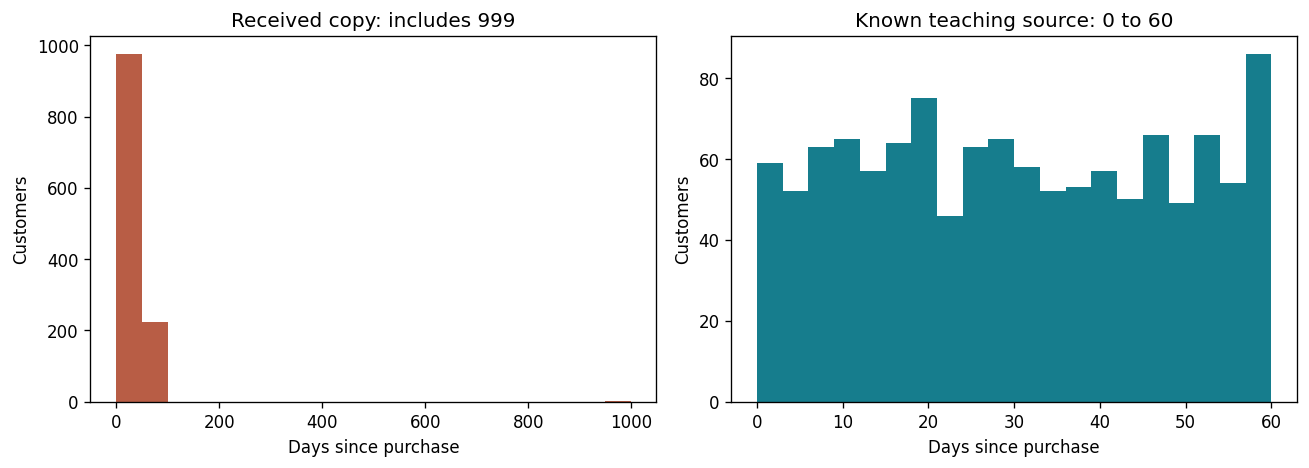

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(raw.days_since_purchase.dropna(), bins=20, color='#b85d45')
axes[0].set(title='Received copy: includes 999', xlabel='Days since purchase', ylabel='Customers')
axes[1].hist(data.days_since_purchase, bins=20, color='#167d8d')
axes[1].set(title='Known teaching source: 0 to 60', xlabel='Days since purchase', ylabel='Customers')
plt.tight_layout(); plt.show()
print('For the modeling experiment below, X and y still come from the known teaching source.')

<div dir="rtl" style="text-align:right"><h2>2 | רואים נתונים ומפרידים לימוד מבדיקה</h2><p>בגרף כל נקודה היא לקוח, והצבע מציין את התשובה הידועה. לקוחות עם אותם ערכים יכולים לקבל תשובות שונות; חיזוי אינו ודאות. <b>אימון</b> משמש ללמידה, <b>אימות</b> משמש להשוואת הגדרות, ו<b>מבחן סופי</b> נשמר עד שבחרנו מודל. שלוש הקבוצות נפרדות.</p><p>אם ננסה שוב ושוב לשפר תוצאה על אותה קבוצת בדיקה, נתחיל להתאים את הבחירות גם אליה. לכן במהלך הניסוי נשתמש באימות; את המבחן הסופי נפתח רק בסוף. בדוגמה חילקנו לקוחות אקראית; בחיזוי עתידי אמיתי לעיתים נכון לחלק לפי זמן.</p></div>

Train: 720 | Validation: 240 | Final test: 240


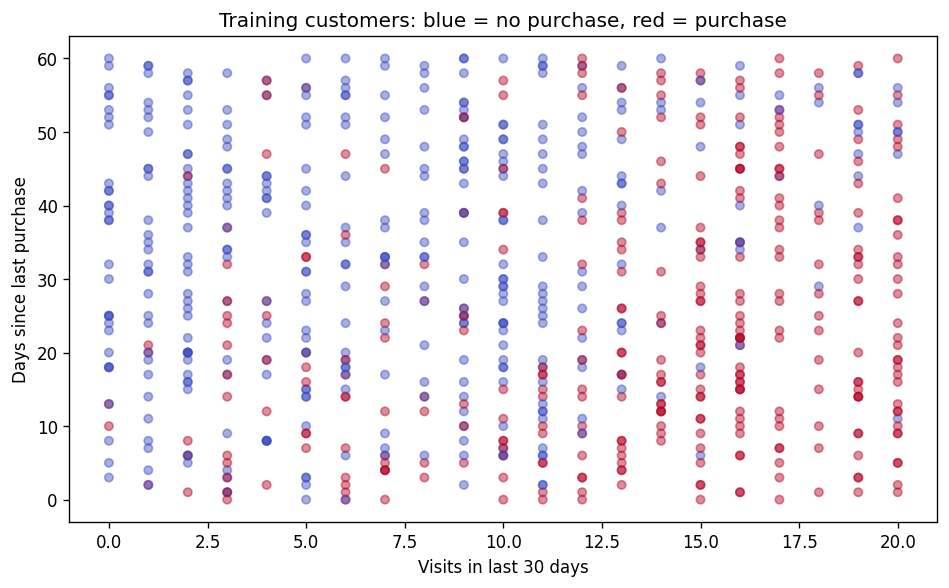

In [6]:
X_pool, X_test, y_pool, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_pool, y_pool, test_size=0.25, stratify=y_pool, random_state=42)
print(f'Train: {len(X_train)} | Validation: {len(X_val)} | Final test: {len(X_test)}')
plt.figure(figsize=(8, 5))
plt.scatter(X_train.visits_30d, X_train.days_since_purchase, c=y_train, cmap='coolwarm', alpha=0.45, s=25)
plt.xlabel('Visits in last 30 days'); plt.ylabel('Days since last purchase')
plt.title('Training customers: blue = no purchase, red = purchase')
plt.tight_layout(); plt.show()

<div dir="rtl" style="text-align:right"><h2>2א | לפני האימון: מהו עץ החלטה?</h2><p><b>עץ החלטה הוא סדרה של שאלות שמובילה לתחזית.</b> בכל צומת שואלים שאלה על תכונה; התשובה בוחרת ענף; בסוף מגיעים לעלה עם תחזית. כדי לחזות לקוח אחד הולכים במסלול אחד בלבד, ולא בכל הענפים.</p><p>בדוגמה המצוירת הבאה השאלות נכתבו ביד להמחשה: האם היו לכל היותר חמישה ביקורים? אם לא, האם הרכישה האחרונה הייתה בעשרת הימים האחרונים? התחזית אינה הבטחה שהלקוח יקנה.</p><ol><li>לקוח א׳: 4 ביקורים ורכישה לפני 8 ימים. באיזה עלה הוא יסתיים? כמה שאלות נשאל?</li><li>לקוח ב׳: 12 ביקורים ורכישה לפני 7 ימים. עקבו אחרי שתי השאלות והציעו תחזית.</li></ol><p><b>עומק</b> הוא מספר השאלות המרבי לאורך מסלול מההתחלה לעלה. בעץ הבא העומק הוא 2, אף שלקוח א׳ עובר שאלה אחת בלבד. עומק אינו מספר השאלות הכולל בכל ענפי העץ.</p><p><b>מי בוחר את השאלות?</b> בדוגמה אנחנו כתבנו אותן. באימון אמיתי האלגוריתם בוחר תכונות וערכי סף מתוך דוגמאות האימון והתוויות שלהן. אנחנו מגדירים אילו נתונים יעמדו לרשותו ומהי המשימה. בהמשך נראה את העץ שלמד בפועל; אין סיבה שיהיה זהה לדוגמה הזאת.</p><h3>איך נבחרת שאלה באימון?</h3><p>דוגמה קטנה ונפרדת: לקוחות עם 2, 4 ו-5 ביקורים לא קנו; לקוחות עם 8, 9, 12 ו-14 ביקורים קנו. סף בין 5 ל-8 מפריד כאן לשתי קבוצות עם תשובות דומות. האלגוריתם משווה פיצולים ומעדיף כאלה שמפחיתים את ערבוב התוויות. זו המחשה בלבד, לא הנתונים שעליהם נאמן בהמשך.</p><p>בעלה מתקבלת תחזית לפי התווית השכיחה בדוגמאות האימון שהגיעו אליו. אם 20 מתוך 36 לא קנו, התחזית היא לא יקנה - אף ש-16 כן קנו. לכן תחזית אחת אינה ודאות. עץ יכול גם ליצור שני עלים עם אותה תחזית, אבל עם הרכב תוויות שונה.</p></div>

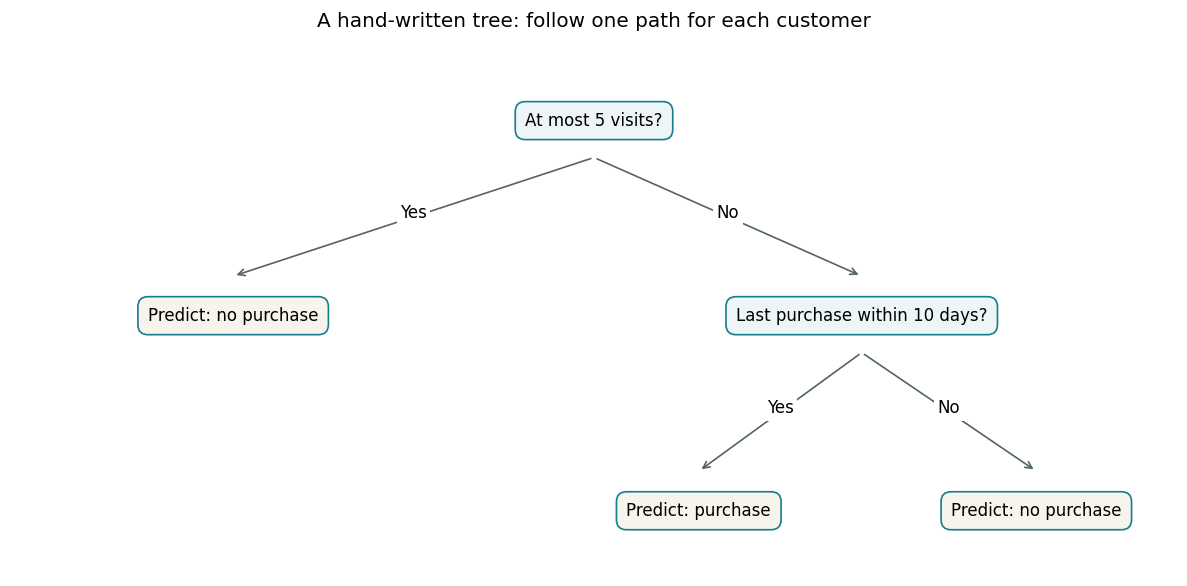

In [7]:
# Hand-written illustration only: this is not the fitted model.
fig, ax = plt.subplots(figsize=(10, 5))
ax.set(xlim=(0, 1), ylim=(0, 1)); ax.axis('off')
positions = {'root':(0.5,0.86), 'left':(0.19,0.49), 'right':(0.73,0.49),
             'yes_leaf':(0.59,0.12), 'no_leaf':(0.88,0.12)}
edges = [('root','left','Yes'),('root','right','No'),('right','yes_leaf','Yes'),('right','no_leaf','No')]
for parent, child, label in edges:
    x1,y1=positions[parent]; x2,y2=positions[child]
    ax.annotate('',xy=(x2,y2+0.075),xytext=(x1,y1-0.07),arrowprops={'arrowstyle':'->','color':'#53636d'})
    ax.text((x1+x2)/2,(y1+y2)/2,label,ha='center',bbox={'facecolor':'white','edgecolor':'none','pad':2})
labels = {'root':'At most 5 visits?', 'left':'Predict: no purchase',
          'right':'Last purchase within 10 days?', 'yes_leaf':'Predict: purchase','no_leaf':'Predict: no purchase'}
for node,(node_x,node_y) in positions.items():
    ax.text(node_x,node_y,labels[node],ha='center',va='center',fontsize=10,
            bbox={'boxstyle':'round,pad=0.6','facecolor':'#edf5f6' if node in ['root','right'] else '#f7f4ec','edgecolor':'#167d8d'})
ax.set_title('A hand-written tree: follow one path for each customer',pad=12)
plt.tight_layout();plt.show()

<div dir="rtl" style="text-align:right"><h2>3 | מאמנים עץ ראשון</h2><p>כעת המחשב יבחר את השאלות מתוך דוגמאות האימון. שנו רק את שתי ההגדרות בראש תא הקוד. את יתר הקוד אין צורך לערוך. השאירו תחילה <b>tree_depth = 2</b> ו-<b>training_examples = 100</b>. הריצו פעם אחת; אחר כך עברו לסעיף 3א כדי לקרוא את העץ ואת מסלול התחזית. אל תשנו עדיין את ההגדרות.</p><p>בטבלת התוצאות: דיוק הוא חלק התשובות הנכונות. קו הבסיס מנחש תמיד את המחלקה השכיחה באימון, בלי להשתמש בתכונות. בגרף הצבע ברקע הוא תחזית המודל; צבע כל נקודה הוא התשובה הידועה ללקוח בקבוצת האימות.</p></div>

Your runs from section 3, in execution order:


,depth,examples,train_accuracy,validation_accuracy,baseline_validation
0,2,100,0.83,0.762,0.542


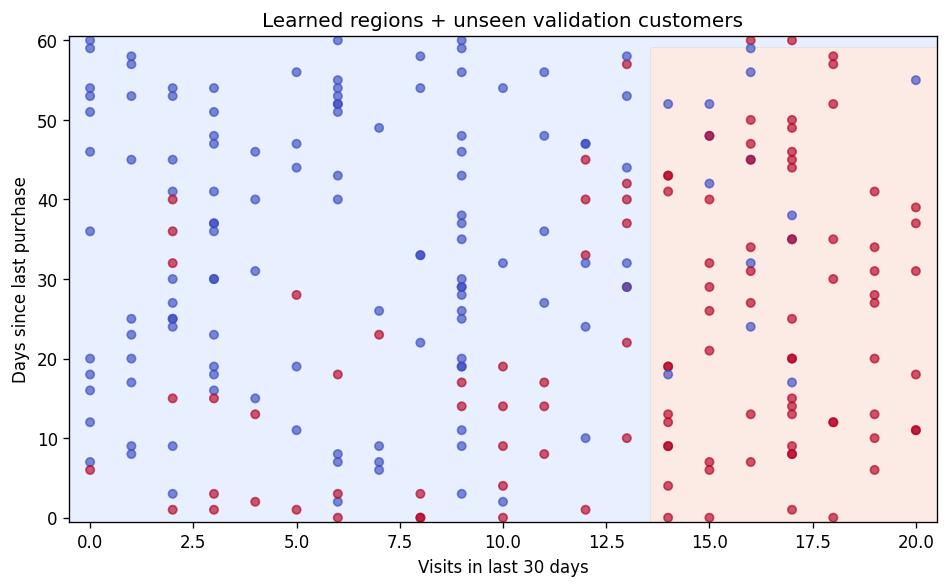

In [8]:
tree_depth = 2 # @param {type:"integer"}
training_examples = 100 # @param {type:"integer"}

# The remaining code runs the experiment; change only the two settings above.
def fit_experiment(depth, count):
    if depth < 0 or not 20 <= count <= len(X_train):
        raise ValueError('Use depth >= 0 and training_examples between 20 and 720.')
    if count == len(X_train):
        x_fit, y_fit = X_train, y_train
    else:
        x_fit, _, y_fit, _ = train_test_split(X_train, y_train, train_size=count, stratify=y_train, random_state=42)
    model = DecisionTreeClassifier(max_depth=None if depth == 0 else depth, random_state=42)
    model.fit(x_fit, y_fit)
    baseline = DummyClassifier(strategy='most_frequent').fit(x_fit, y_fit)
    row = {'depth': 'unlimited' if depth == 0 else depth, 'examples': count,
           'train_accuracy': accuracy_score(y_fit, model.predict(x_fit)),
           'validation_accuracy': accuracy_score(y_val, model.predict(X_val)),
           'baseline_validation': accuracy_score(y_val, baseline.predict(X_val))}
    return model, row

model, result = fit_experiment(tree_depth, training_examples)
experiment_log = globals().get('experiment_log', [])
experiment_log.append(result.copy())
print('Your runs from section 3, in execution order:')
display(pd.DataFrame(experiment_log).round(3))
gx, gy = np.meshgrid(np.linspace(-0.5,20.5,160), np.linspace(-0.5,60.5,160))
grid = pd.DataFrame({'visits_30d': gx.ravel(), 'days_since_purchase': gy.ravel()})
fig, ax = plt.subplots(figsize=(8,5))
ax.contourf(gx, gy, model.predict(grid).reshape(gx.shape), levels=[-0.5,0.5,1.5], cmap='coolwarm', alpha=0.2)
ax.scatter(X_val.visits_30d, X_val.days_since_purchase, c=y_val, cmap='coolwarm', s=25, alpha=0.65)
ax.set(xlabel='Visits in last 30 days', ylabel='Days since last purchase', title='Learned regions + unseen validation customers')
plt.tight_layout(); plt.show()

<div dir="rtl" style="text-align:right"><h2>3א | קוראים את העץ שהמודל למד בפועל</h2><p>עצרו כאן לפני שמשנים עומק. ההרצה הראשונה בסעיף 3 היא בעומק 2 ועם 100 דוגמאות. התרשים הבא מציג את <b>אותו מודל</b> שאימנתם, ולא את הדוגמה הידנית. ערכי הסף יכולים להיות שונים.</p><p>מקרא: Visits in 30 days = ביקורים ב-30 ימים; Days since purchase = ימים מאז הרכישה; No / Yes = מספר הלא-קונים והקונים באימון שהגיעו לעלה. בכל שאלה, שמאלה פירושו שהערך קטן מהסף או שווה לו; ימינה פירושו שהוא גדול מהסף. בעלה מופיעים התחזית, מספר דוגמאות האימון, וכמה מהן לא קנו או קנו: No / Yes. לדוגמה, סף 13.5 מפריד ביקורים שלמים של 13 ומטה מ-14 ומעלה. יותר דוגמאות בעלה אינן מבטיחות תחזית נכונה.</p><p>לפני הריצה, חזו את המסלול של לקוח עם 12 ביקורים ורכישה לפני 7 ימים. לאחר ההרצה קראו את טבלת המסלול: איזו תכונה נבדקה, איזה ערך הוזן, איזו תשובה התקבלה ולאיזה צומת המשכנו? השוו את תחזית העלה לתחזית שהמודל החזיר. אם התחזית שונה מזו של עץ ההמחשה, זה צפוי: כאן השאלות נלמדו מהנתונים. עקבו גם אחרי לקוח עם 14 ביקורים ו-7 ימים בלי להריץ חיזוי, ונמקו איזו שאלה שינתה את המסלול.</p><p>רק אחרי שאתם מסוגלים לעקוב אחרי מסלול אחד, עברו לניסוי העומקים בסעיף 4. אם שיניתם את המודל בסעיף 3, הריצו מחדש גם את הסעיף הזה כדי לראות את העץ המעודכן.</p></div>

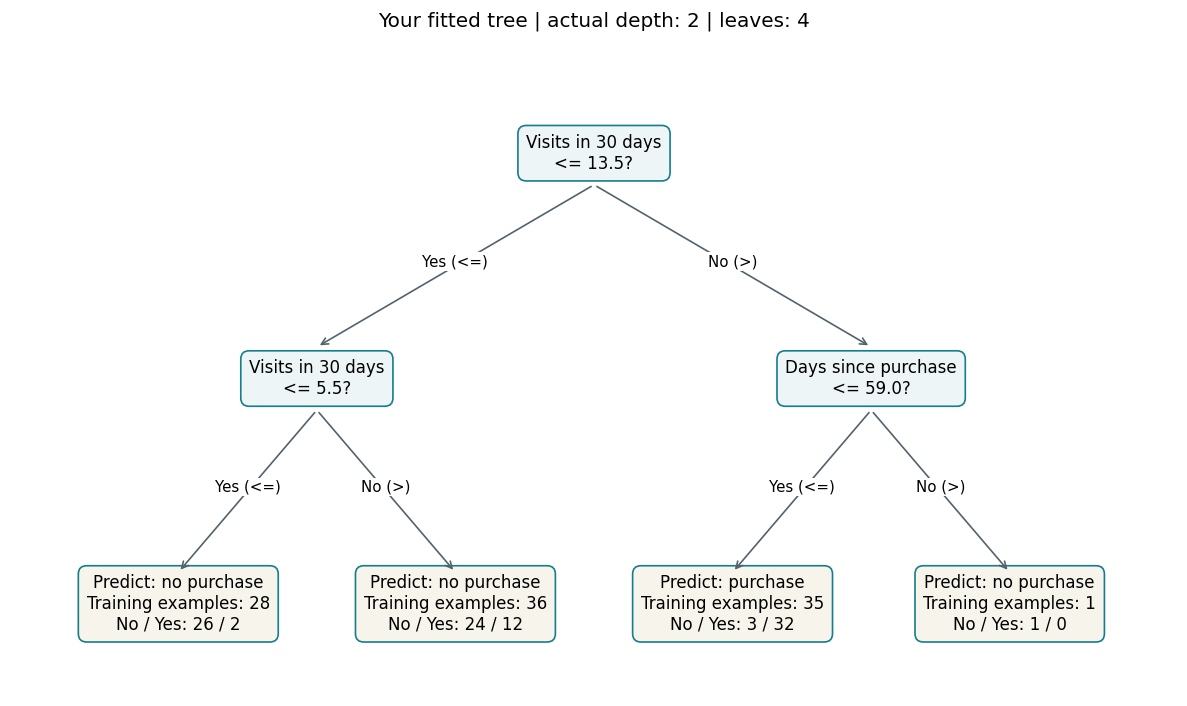

In [9]:
# Draw exactly the fitted model when it is small enough to read.
t = model.tree_
feature_labels = ['Visits in 30 days','Days since purchase']
if model.get_depth() <= 3:
    positions = {}; next_leaf = [0]
    def place_node(node, depth=0):
        if t.children_left[node] == t.children_right[node]:
            x = next_leaf[0]; next_leaf[0] += 1
        else:
            x = (place_node(t.children_left[node], depth+1) + place_node(t.children_right[node], depth+1))/2
        positions[node] = (x, -depth)
        return x
    place_node(0)
    fig, ax = plt.subplots(figsize=(max(10,next_leaf[0]*2.1),6))
    ax.axis('off')
    for node,(x,yy) in positions.items():
        leaf = t.children_left[node] == t.children_right[node]
        if leaf:
            predicted_class = int(model.classes_[np.argmax(t.value[node][0])])
            counts = np.rint(t.value[node][0] / t.value[node][0].sum() * t.weighted_n_node_samples[node]).astype(int)
            label = ('Predict: purchase' if predicted_class else 'Predict: no purchase') + f'\nTraining examples: {t.n_node_samples[node]}\nNo / Yes: {counts[0]} / {counts[1]}'
        else:
            label = feature_labels[t.feature[node]] + f'\n<= {t.threshold[node]:.1f}?'
            for child,answer in [(t.children_left[node],'Yes (<=)'),(t.children_right[node],'No (>)')]:
                cx,cy=positions[child]
                ax.annotate('',xy=(cx,cy+0.14),xytext=(x,yy-0.14),arrowprops={'arrowstyle':'->','color':'#53636d'})
                ax.text((x+cx)/2,(yy+cy)/2,answer,ha='center',fontsize=9,bbox={'facecolor':'white','edgecolor':'none','pad':1})
        ax.text(x,yy,label,ha='center',va='center',fontsize=10,
                bbox={'boxstyle':'round,pad=0.5','facecolor':'#f7f4ec' if leaf else '#edf5f6','edgecolor':'#167d8d'})
    ax.set_xlim(-0.6,max(positions[n][0] for n in positions)+0.6)
    ax.set_ylim(-model.get_depth()-0.4,0.45)
    ax.set_title(f'Your fitted tree | actual depth: {model.get_depth()} | leaves: {model.get_n_leaves()}',pad=15)
    plt.tight_layout();plt.show()
else:
    print('This fitted tree is too deep for a readable full picture. Choose depth 2 or 3 in section 3 and rerun here.')
    print('The path below still follows the full fitted tree.')

example = pd.DataFrame({'visits_30d':[12], 'days_since_purchase':[7]})
node=0; route=[]
while t.children_left[node] != t.children_right[node]:
    feature=int(t.feature[node]); value=float(example.iloc[0,feature]); threshold=float(t.threshold[node])
    answer=value <= threshold
    following=int(t.children_left[node] if answer else t.children_right[node])
    route.append({'node':node,'question':f'{feature_labels[feature]} <= {threshold:.1f}?',
                  'customer_value':value,'answer':'Yes' if answer else 'No','next_node':following})
    node=following
display(example)
display(pd.DataFrame(route))
leaf_prediction = int(model.classes_[np.argmax(t.value[node][0])])
prediction_from_model = int(model.predict(example)[0])
assert leaf_prediction == prediction_from_model
assert node == int(model.apply(example)[0])
print(f'Reached leaf {node} after {len(route)} questions.')
print('Prediction:', 'purchase' if prediction_from_model else 'no purchase')

<div dir="rtl" style="text-align:right"><h2>4 | האם מורכבות תמיד עוזרת?</h2><p><b>עכשיו משנים:</b> חזרו לסעיף 3, נסו עומקים 1, 3 ו-0 עם 100 דוגמאות; כאן 0 פירושו ללא הגבלת עומק. נבאו השפעה לפני כל שינוי. אחר כך בחרו עומק אחד ושנו רק את מספר הדוגמאות ל-300. השאירו את אותם נתונים ואותו פיצול.</p><p>הטבלה בסעיף 3 שומרת את הריצות שלכם. הטבלה הבאה היא השוואה מוכנה של 100 דוגמאות בלבד; היא אינה מחליפה את תיעוד ניסוי ה-300 שלכם. התאמת יתר היא מצב שבו המודל מותאם היטב לדוגמאות האימון, אך חלק מההתאמה הוא לפרטים מקריים שאינם חוזרים בנתונים חדשים. פער גדול בין אימון לאימות הוא סימן אזהרה. מודל רדוד מדי עשוי להחמיץ גם דפוסים מועילים.</p><blockquote>האם 100% באימון מספיקים כדי לבחור מודל? האם יותר נתונים תמיד ישפרו כל ריצה? השתמשו במספרים מהטבלה, והימנעו ממסקנה כללית מריצה אחת.</blockquote></div>

,depth,examples,train_accuracy,validation_accuracy,baseline_validation
0,1,100,0.82,0.771,0.542
1,3,100,0.85,0.767,0.542
2,unlimited,100,0.97,0.708,0.542


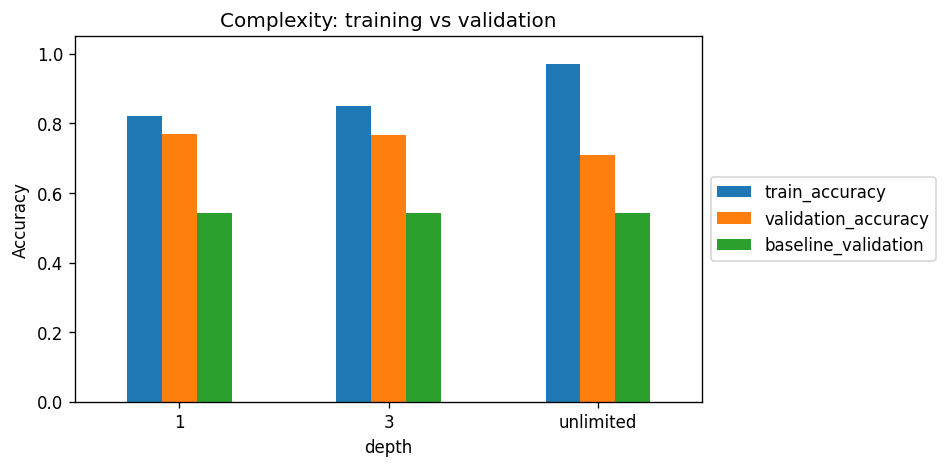

In [10]:
comparison = pd.DataFrame([fit_experiment(d, 100)[1] for d in [1, 3, 0]])
display(comparison.round(3))
comparison.set_index('depth')[['train_accuracy','validation_accuracy','baseline_validation']].plot.bar(figsize=(8,4), ylim=(0,1.05), rot=0)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5)); plt.ylabel('Accuracy'); plt.title('Complexity: training vs validation'); plt.tight_layout(); plt.show()

<div dir="rtl" style="text-align:right"><h2>5 | אילו טעויות מסתתרות מאחורי הדיוק?</h2><p>מטריצת הטעויות סופרת מה קרה בפועל מול מה שחזינו. בשורות נמצאת התשובה האמיתית; בעמודות החיזוי. כאן 1 פירושו קנה ו-0 פירושו לא קנה. <b>Precision</b>: מתוך מי שחזינו שיקנו, כמה אכן קנו? <b>Recall</b>: מתוך מי שקנו, כמה זיהינו?</p><p>המודל בתא הבא הוא זה מהריצה האחרונה בסעיף 3. שאלו: מה המחיר של לפספס קונה? מה המחיר של לפנות למי שלא יקנה? חיזוי רכישה אינו מוכיח שפנייה תגרום לרכישה.</p></div>

Separate thought experiment: 90 non-buyers + 10 buyers.
Always predict no purchase -> accuracy 90%, buyer recall 0%.


,accuracy,precision,recall
0,0.762,0.827,0.609


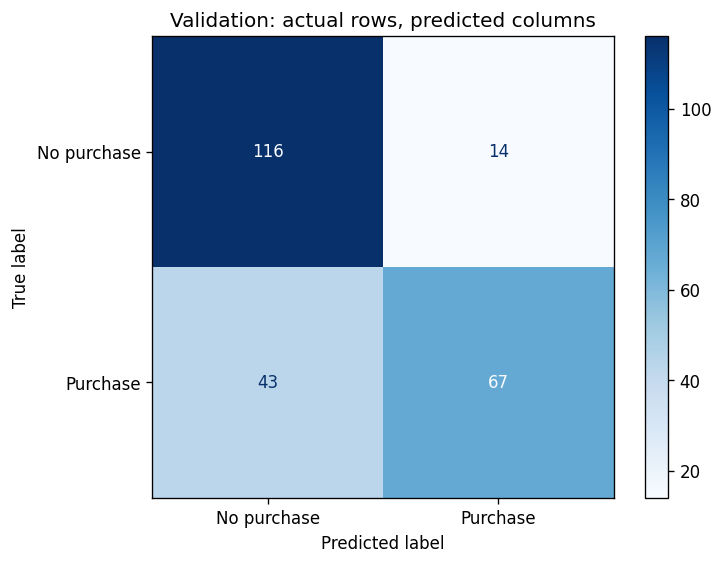

In [11]:
prediction = model.predict(X_val)
display(pd.DataFrame([{'accuracy': accuracy_score(y_val,prediction),
                      'precision': precision_score(y_val,prediction,zero_division=0),
                      'recall': recall_score(y_val,prediction,zero_division=0)}]).round(3))
ConfusionMatrixDisplay.from_predictions(y_val, prediction, labels=[0,1], display_labels=['No purchase','Purchase'], cmap='Blues')
plt.title('Validation: actual rows, predicted columns'); plt.tight_layout(); plt.show()
print('Separate thought experiment: 90 non-buyers + 10 buyers.')
print('Always predict no purchase -> accuracy 90%, buyer recall 0%.')

<div dir="rtl" style="text-align:right"><h2>6 | חיזוי לקוח חדש ושיחה עם הצ׳טבוט</h2><p>בחרו ערכי לקוח חדש. זהו שימוש במודל שכבר אומן, ולא אימון נוסף. התוצאה תלויה בריצה האחרונה בסעיף 3. נסו שני לקוחות והסבירו מה השתנה.</p><blockquote>בקשה לצ׳טבוט: אני לומד ללא רקע בתכנות. הנה הקוד, ההגדרות והתוצאות שלי: [הדביקו]. הסבר מה למד המודל, במה נבדלים אימון ואימות, והצע ניסוי אחד שמשנה משתנה אחד בלבד. שאל אותי מה אני מצפה שיקרה לפני שאתה מסביר את התוצאה. אל תמציא תוצאות ואל תשתמש בנתוני המבחן הסופי לבחירת הגדרות.</blockquote></div>

In [12]:
new_visits = 12 # @param {type:"integer"}
new_days = 7 # @param {type:"integer"}
if not 0 <= new_visits <= 20 or not 0 <= new_days <= 60:
    raise ValueError('Stay inside the teaching data range: visits 0..20, days 0..60.')
new_customer = pd.DataFrame({'visits_30d':[new_visits], 'days_since_purchase':[new_days]})
display(new_customer)
print('Prediction (1 = purchase):', int(model.predict(new_customer)[0]))

Prediction (1 = purchase): 0


,visits_30d,days_since_purchase
0,12,7


<div dir="rtl" style="text-align:right"><h2>7 | הדגמה קצרה והרחבה לבחירה: אשכול לקוחות</h2><p>כעת השאלה שונה: האם יש קבוצות של לקוחות בעלי מאפיינים דומים? יוצרים טבלה בדויה נפרדת של תדירות ביקור והוצאה ממוצעת. <b>אין תווית של קבוצה נכונה ואין שימוש בתווית הרכישה.</b> K-Means מחלק לקבוצות לפי קרבה, לאחר התאמת קנה המידה של התכונות.</p><p>נסו 2, 3 ו-5 קבוצות. המספרים 0, 1 וכו׳ הם מזהים שרירותיים, לא דירוגי איכות. מספר הקבוצות נקבע על ידינו; עצם קבלת צבעים בגרף אינה הוכחה לקיומן של קבוצות עסקיות טבעיות. הסתכלו גם על ממוצעי הקבוצות והציעו פירוש זהיר.</p></div>

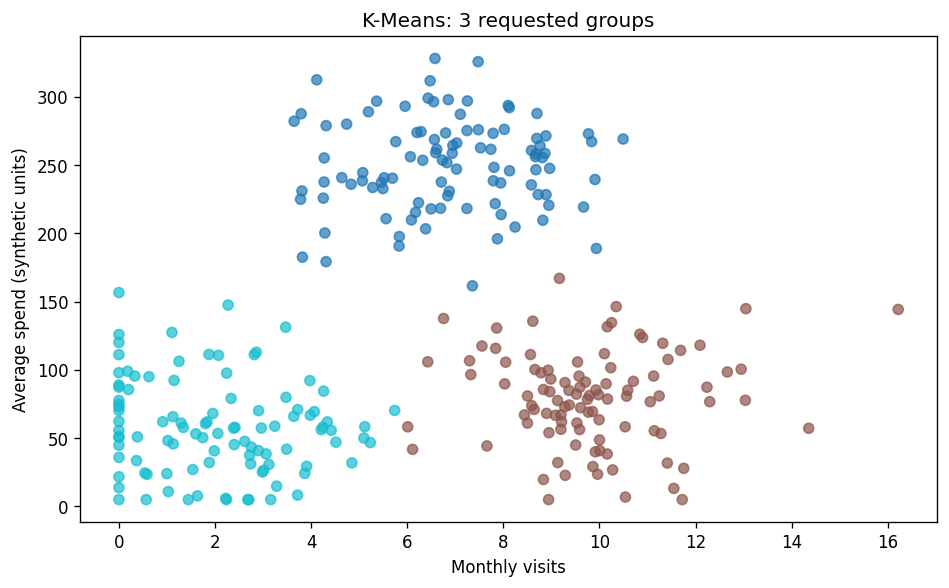

,customers,visits,spend
cluster,,,
0,100,6.9,250.1
1,99,9.8,79.4
2,101,2.0,58.2


In [13]:
cluster_rng = np.random.default_rng(17)
centers = np.array([[2,55],[10,80],[7,250]])
blocks = [cluster_rng.normal(loc=center, scale=[1.8,35], size=(100,2)) for center in centers]
customers = pd.DataFrame(np.clip(np.vstack(blocks), [0,5], [20,400]), columns=['monthly_visits','average_spend'])
scaled = StandardScaler().fit_transform(customers)
number_of_clusters = 3 # @param {type:"integer"}
if not 2 <= number_of_clusters <= 6:
    raise ValueError('Choose 2 to 6 clusters for this exercise.')
kmeans = KMeans(n_clusters=number_of_clusters, random_state=42, n_init=10)
groups = kmeans.fit_predict(scaled)
fig, ax = plt.subplots(figsize=(8,5))
ax.scatter(customers.monthly_visits, customers.average_spend, c=groups, cmap='tab10', alpha=0.7)
ax.set(xlabel='Monthly visits', ylabel='Average spend (synthetic units)', title=f'K-Means: {number_of_clusters} requested groups')
plt.tight_layout(); plt.show()
summary = customers.assign(cluster=groups).groupby('cluster').agg(customers=('monthly_visits','size'), visits=('monthly_visits','mean'), spend=('average_spend','mean'))
display(summary.round(1))

<div dir="rtl" style="text-align:right"><h2>8 | בוחרים, ואז פותחים מבחן סופי</h2><p>כתבו את בחירתכם ואת הנימוק על סמך קבוצת האימות. בתא הבא כתבו את הנימוק בשדה choice_reason וסמנו ready_for_final_test רק אחרי הבחירה. הרצה בלי אישור אינה חושפת את המבחן. ההגדרות כאן נפרדות מסעיף 3; עדכנו אותן לבחירה שלכם. אל תבחרו מחדש לפי התוצאה הסופית. אם משנים בחירה בעקבותיה, הקבוצה הזו כבר אינה מבחן סופי עצמאי.</p><p>גם מבחן שנשמר בצד אינו מבטיח הצלחה בעולם: לקוחות, זמן ונתונים עשויים להשתנות. בדוגמה כל הקבוצות נוצרו באותה נוסחה בדויה.</p></div>

In [ ]:
chosen_depth = 2 # @param {type:"integer"}
chosen_training_examples = 100 # @param {type:"integer"}
choice_reason = "" # @param {type:"string"}
ready_for_final_test = False # @param {type:"boolean"}

if not ready_for_final_test or not choice_reason.strip():
    print('המבחן עדיין סגור. בחרו הגדרות לפי האימות, כתבו נימוק ב-choice_reason ורק אז סמנו ready_for_final_test.')
else:
    print('Chosen before the final test:', chosen_depth, chosen_training_examples)
    print('Reason:', choice_reason)
    final_model, _ = fit_experiment(chosen_depth, chosen_training_examples)
    final_prediction = final_model.predict(X_test)
    display(pd.DataFrame([{'final_test_accuracy':accuracy_score(y_test,final_prediction),
                          'final_test_precision':precision_score(y_test,final_prediction,zero_division=0),
                          'final_test_recall':recall_score(y_test,final_prediction,zero_division=0)}]).round(3))


<div dir="rtl" style="text-align:right"><h2>9 | מסכמים ומנגישים</h2><p><b>בדיקת הבנה ללא צ׳טבוט, לפני שמשווים תשובות בצוות:</b> (1) עקבו אחרי הלקוח עם 14 ביקורים ו-7 ימים בעץ שנלמד והסבירו את המסלול; (2) מודל השיג 100% באימון ו-60% באימות, מול מודל שהשיג 85% ו-76% - איזה מהם מבטיח יותר לחיזוי חדש ומדוע? (3) הסבירו למה טעות אחת אינה בהכרח תקלה בקוד. לאחר תשובה עצמאית אפשר לבקש מהצ׳טבוט להצביע על חור בהסבר שלכם.</p><p>הסבירו במילים שלכם: מהי תכונה, מהי תווית, במה סיווג שונה מאשכול, ולמה ציון אימון גבוה אינו מספיק. כתבו תצפית אחת שהפתיעה אתכם ושאלה אחת שעדיין פתוחה.</p><p>כדי לשתף עותק של המחברת, השתמשו בשיתוף ב-Colab/Drive ובחרו הרשאת צפייה המתאימה למדיניות החשבון. הקישור מציג מחברת ולא אתר עצמאי. מי שירצה להריץ עשוי להידרש להתחבר וליצור עותק משלו. בדקו את הקישור עם חבר צוות אחר; אל תשתפו נתונים אישיים. חקרו עם הצ׳טבוט איזו דרך אחרת תתאים למשתמש שאינו מכיר קולאב. אין במטלה זו דרישה לפרסם אפליקציה חדשה.</p><h3>מקורות להסברים ולקוד</h3><p>scikit-learn: <a href="https://scikit-learn.org/stable/modules/tree.html">Decision trees</a>, <a href="https://scikit-learn.org/stable/modules/cross_validation.html">Model evaluation</a>, <a href="https://scikit-learn.org/stable/modules/clustering.html">Clustering</a>. אין צורך לקרוא אותם ידנית לקראת התרגיל; אפשר לבקש מהצ׳טבוט להסביר קטע רלוונטי.</p></div>